# Building a Stock Data Pipeline with Python Classes (Alpha Vantage API and SQL Repository) and a Return Comparison: Ambuja Cement vs. Suzlon

1. Test assertion yang lolos

x = 42 lalu assert x == 42. Karena benar, tidak ada output. Assertion dipakai sebagai “pagar” validasi.

In [17]:
# A passing assertion — nothing happens
x = 42
assert x == 42, f"Expected 42, got {x}"

2. Test assertion yang gagal (dikomentari)

Contoh assert y > 100 yang sengaja dinonaktifkan agar notebook tidak error. Jika diaktifkan, akan memunculkan AssertionError beserta pesannya.

In [18]:
# A failing assertion — uncomment to see the error
# y = 10
# assert y > 100, f"Expected y > 100, got {y}"

3. Kelas Greeter

Demo dasar OOP: __init__ menyimpan name ke dalam objek lewat self, dan method greet() mengembalikan sapaan. Output: Hello, World!.

In [19]:
class Greeter:
    """Minimal class to illustrate __init__ and a method."""

    def __init__(self, name):
        # Store data inside the object using 'self'
        self.name = name

    def greet(self):
        # Methods can access stored data via 'self'
        return f"Hello, {self.name}!"


g = Greeter("World")
print(g.greet())
print("Attribute 'name':", g.name)

Hello, World!
Attribute 'name': World


4. Objek kedua g2

Membuat instance lain ("Python") untuk menunjukkan setiap objek menyimpan data sendiri-sendiri.

In [20]:
g2 = Greeter("Python")
print(g2.greet())  # "Hello, Python!" — independent of g

Hello, Python!


5. Demo SQLite di memori

Membuat database :memory:, DataFrame kecil dengan indeks tanggal, menulisnya ke tabel demo_prices via to_sql, lalu membacanya kembali dengan read_sql (parse_dates, index_col) sehingga indeks kembali berupa DatetimeIndex.

In [21]:
import sqlite3
import pandas as pd

# Create an in-memory database for demonstration
demo_conn = sqlite3.connect(":memory:")

# Create a small DataFrame
demo_df = pd.DataFrame(
    {"date": ["2024-01-01", "2024-01-02"], "close": [100.0, 102.5]}
)
demo_df["date"] = pd.to_datetime(demo_df["date"])
demo_df.set_index("date", inplace=True)

# Write to SQLite
demo_df.to_sql("demo_prices", demo_conn, if_exists="replace")

# Read back
result = pd.read_sql(
    "SELECT * FROM demo_prices",
    demo_conn,
    parse_dates=["date"],
    index_col="date",
)
print(result)
print("Type of index:", type(result.index))

demo_conn.close()

            close
date             
2024-01-01  100.0
2024-01-02  102.5
Type of index: <class 'pandas.DatetimeIndex'>


6. Demo return persen

pct_change() * 100 pada 4 harga mainan menghasilkan return dalam persen (NaN, 2,00, −2,94, 2,53).

In [22]:
demo_prices = pd.Series(
    [100.0, 102.0, 99.0, 101.5],
    index=pd.date_range("2024-01-01", periods=4),
    name="close",
)
demo_returns = demo_prices.pct_change() * 100
print(demo_returns)

2024-01-01         NaN
2024-01-02    2.000000
2024-01-03   -2.941176
2024-01-04    2.525253
Freq: D, Name: close, dtype: float64


7. Import utama

Mengimpor sqlite3, matplotlib, pandas, serta activate_mock/deactivate_mock.

In [23]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from mock_alpha import activate_mock, deactivate_mock

8. activate_mock()

Mengaktifkan mock agar request ke Alpha Vantage tidak benar-benar keluar ke internet.

In [24]:
activate_mock()

9. Membuat objek AlphaVantageAPI

av = AlphaVantageAPI() dari modul data; mencetak tipe objek untuk memastikan kelas berhasil dibuat.

In [25]:
from data import AlphaVantageAPI

av = AlphaVantageAPI()
print("av type:", type(av))

av type: <class 'data.AlphaVantageAPI'>


10. av.get_daily("AMBUJACEM.BSE")

Mengambil data harian Ambuja Cement ke df_ambuja (5.225 baris × 5 kolom: open, high, low, close, volume).

In [26]:
ticker_ambuja = "AMBUJACEM.BSE"
df_ambuja = av.get_daily(ticker=ticker_ambuja)

print("df_ambuja type:", type(df_ambuja))
print("df_ambuja shape:", df_ambuja.shape)
df_ambuja.head()

df_ambuja type: <class 'pandas.DataFrame'>
df_ambuja shape: (5225, 5)


,open,high,low,close,volume
date,,,,,
2005-01-03,405.0001,409.5001,403.1001,407.6001,1061050.0
2005-01-04,410.0001,429.0001,409.0001,425.8501,2501549.0
2005-01-05,427.0001,439.9001,406.1501,425.9501,3537669.0
2005-01-06,426.0001,431.0001,412.0001,416.0501,3103853.0
2005-01-07,420.0001,428.5001,418.0001,426.3001,2330736.0


11. Uji AlphaVantageAPI

Enam assertion: bertipe DataFrame, 5 kolom, DatetimeIndex, indeks bernama date, nama kolom benar, dan semua kolom float.

In [27]:
# 1. Is df_ambuja a DataFrame?
assert isinstance(
    df_ambuja, pd.DataFrame
), f"Expected pd.DataFrame, got {type(df_ambuja)}"

# 2. Does it have exactly 5 columns?
assert (
    df_ambuja.shape[1] == 5
), f"Expected 5 columns, got {df_ambuja.shape[1]}"

# 3. Does it have a DatetimeIndex?
assert isinstance(
    df_ambuja.index, pd.DatetimeIndex
), f"Expected DatetimeIndex, got {type(df_ambuja.index)}"

# 4. Is the index named 'date'?
assert (
    df_ambuja.index.name == "date"
), f"Expected index name 'date', got '{df_ambuja.index.name}'"

# 5. Are the column names correct?
expected_cols = ["open", "high", "low", "close", "volume"]
assert (
    df_ambuja.columns.tolist() == expected_cols
), f"Expected columns {expected_cols}, got {df_ambuja.columns.tolist()}"

# 6. Are all column dtypes float?
assert all(
    df_ambuja.dtypes == float
), f"Column dtypes: {df_ambuja.dtypes.tolist()}"

print("All AlphaVantageAPI tests passed.")

All AlphaVantageAPI tests passed.


12. Checkpoint API

Pengecekan ulang yang sama dalam bentuk ringkas, lalu mencetak “Checkpoint passed”.

In [28]:
# --- AlphaVantageAPI checkpoint ---
assert isinstance(
    df_ambuja, pd.DataFrame
), f"df_ambuja should be a DataFrame, got {type(df_ambuja)}"
assert df_ambuja.shape[1] == 5, (
    f"Expected 5 columns, got {df_ambuja.shape[1]}"
)
assert isinstance(
    df_ambuja.index, pd.DatetimeIndex
), f"Index should be DatetimeIndex, got {type(df_ambuja.index)}"
assert df_ambuja.index.name == "date", (
    f"Index name should be 'date', got '{df_ambuja.index.name}'"
)
assert df_ambuja.columns.tolist() == [
    "open", "high", "low", "close", "volume"
], f"Unexpected columns: {df_ambuja.columns.tolist()}"
assert all(df_ambuja.dtypes == float), (
    f"All columns should be float: {df_ambuja.dtypes.tolist()}"
)
print(
    "Checkpoint passed: AlphaVantageAPI returns a valid "
    f"DataFrame with shape {df_ambuja.shape}."
)

Checkpoint passed: AlphaVantageAPI returns a valid DataFrame with shape (5225, 5).


13. Koneksi SQLite

sqlite3.connect("stocks.sqlite", check_same_thread=False) membuat/menghubungkan ke file database lokal.

In [29]:
connection = sqlite3.connect(
    database="stocks.sqlite", check_same_thread=False
)
print("connection type:", type(connection))

connection type: <class 'sqlite3.Connection'>


14. Kelas SQLRepository

Membuat repo = SQLRepository(connection=connection) dan menguji atribut connection ada serta bertipe sqlite3.Connection.

In [30]:
from data import SQLRepository

repo = SQLRepository(connection=connection)

# Test: does repo have a 'connection' attribute?
assert hasattr(repo, "connection"), "SQLRepository missing 'connection' attribute"

# Test: is it a sqlite3.Connection?
assert isinstance(repo.connection, sqlite3.Connection), (
    f"Expected sqlite3.Connection, got {type(repo.connection)}"
)
print("SQLRepository __init__ tests passed.")

SQLRepository __init__ tests passed.


15. repo.insert_table

Menyimpan df_ambuja ke tabel df_ambuja (if_exists="replace"). Respons berupa dict: transaction_successful=True, records_inserted=5225. Ada assertion untuk tipe dan kunci dict.

In [31]:
response = repo.insert_table(
    table_name="df_ambuja",
    records=df_ambuja,
    if_exists="replace",
)

# Test: response is a dict?
assert isinstance(response, dict), (
    f"Expected dict, got {type(response)}"
)

# Test: correct keys?
expected_keys = ["records_inserted", "transaction_successful"]
assert sorted(response.keys()) == expected_keys, (
    f"Expected keys {expected_keys}, got {sorted(response.keys())}"
)

print("insert_table response:", response)

insert_table response: {'transaction_successful': True, 'records_inserted': 5225}


16. repo.read_table(limit=2500)

Membaca kembali tabel dari database, hanya 2.500 baris (shape 2500×5).

In [32]:
df_ambuja = repo.read_table(table_name="df_ambuja", limit=2500)

print("read_table tests passed.")
print("df_ambuja shape:", df_ambuja.shape)
df_ambuja.head()

read_table tests passed.
df_ambuja shape: (2500, 5)


,open,high,low,close,volume
date,,,,,
2005-01-03,405.0001,409.5001,403.1001,407.6001,1061050.0
2005-01-04,410.0001,429.0001,409.0001,425.8501,2501549.0
2005-01-05,427.0001,439.9001,406.1501,425.9501,3537669.0
2005-01-06,426.0001,431.0001,412.0001,416.0501,3103853.0
2005-01-07,420.0001,428.5001,418.0001,426.3001,2330736.0


17. Checkpoint SQLRepository

Memvalidasi koneksi, tipe DataFrame, DatetimeIndex, nama indeks date, 5 kolom, dan tipe float.

In [33]:
# --- SQLRepository checkpoint ---
assert isinstance(
    repo.connection, sqlite3.Connection
), "repo.connection is not a sqlite3.Connection"
assert isinstance(
    df_ambuja, pd.DataFrame
), f"df_ambuja should be a DataFrame, got {type(df_ambuja)}"
assert isinstance(
    df_ambuja.index, pd.DatetimeIndex
), f"Index should be DatetimeIndex, got {type(df_ambuja.index)}"
assert df_ambuja.index.name == "date", (
    f"Index name should be 'date', got '{df_ambuja.index.name}'"
)
assert df_ambuja.shape[1] == 5, (
    f"Expected 5 columns, got {df_ambuja.shape[1]}"
)
assert all(df_ambuja.dtypes == float), (
    f"All columns should be float: {df_ambuja.dtypes.tolist()}"
)
print(
    "Checkpoint passed: SQLRepository insert and read work "
    f"correctly. df_ambuja shape: {df_ambuja.shape}."
)

Checkpoint passed: SQLRepository insert and read work correctly. df_ambuja shape: (2500, 5).


18. Mengambil saham kedua (Suzlon)

av.get_daily("SUZLON.BSE") lalu insert_table ke tabel ticker_suzlon (5.031 baris tersimpan).


In [34]:
ticker_suzlon = "SUZLON.BSE"

# Fetch data
df_suzlon_raw = av.get_daily(ticker=ticker_suzlon)

# Insert into database
response = repo.insert_table(
    table_name="ticker_suzlon",
    records=df_suzlon_raw,
    if_exists="replace",
)
print("insert response:", response)

insert response: {'transaction_successful': True, 'records_inserted': 5031}


19. Membaca Suzlon dari DB

read_table("ticker_suzlon", limit=2500) menghasilkan df_suzlon (2500×5), data mulai 2005-10-20.

In [35]:
df_suzlon = repo.read_table(
    table_name="ticker_suzlon", limit=2500
)
print("df_suzlon shape:", df_suzlon.shape)
df_suzlon.head()

df_suzlon shape: (2500, 5)


,open,high,low,close,volume
date,,,,,
2005-10-20,697.0003,709.8002,637.0002,647.4003,22683542.0
2005-10-21,644.4502,685.1003,637.0002,673.1503,14260538.0
2005-10-24,683.0003,689.5502,648.0003,653.3503,7340714.0
2005-10-25,654.0003,663.9003,642.2503,659.0003,4034972.0
2005-10-26,660.0003,693.4503,650.1003,687.9003,8950423.0


20. Checkpoint saham kedua

Memastikan df_suzlon tidak kosong, 5 kolom, dan berindeks DatetimeIndex.

In [36]:
# --- Second stock checkpoint ---
assert isinstance(
    df_suzlon, pd.DataFrame
), f"df_suzlon should be a DataFrame, got {type(df_suzlon)}"
assert df_suzlon.shape[0] > 0, "df_suzlon is empty"
assert df_suzlon.shape[1] == 5, (
    f"Expected 5 columns, got {df_suzlon.shape[1]}"
)
assert isinstance(
    df_suzlon.index, pd.DatetimeIndex
), f"Index should be DatetimeIndex, got {type(df_suzlon.index)}"
print(
    "Checkpoint passed: Suzlon data loaded with shape "
    f"{df_suzlon.shape}."
)

Checkpoint passed: Suzlon data loaded with shape (2500, 5).


21. deactivate_mock()

Mengembalikan perilaku normal requests.

In [37]:
deactivate_mock()

22. Plot harga penutupan

Mengurutkan kedua DataFrame secara kronologis (sort_index), lalu memplot harga close AMBUJACEM dan SUZLON dalam satu grafik.

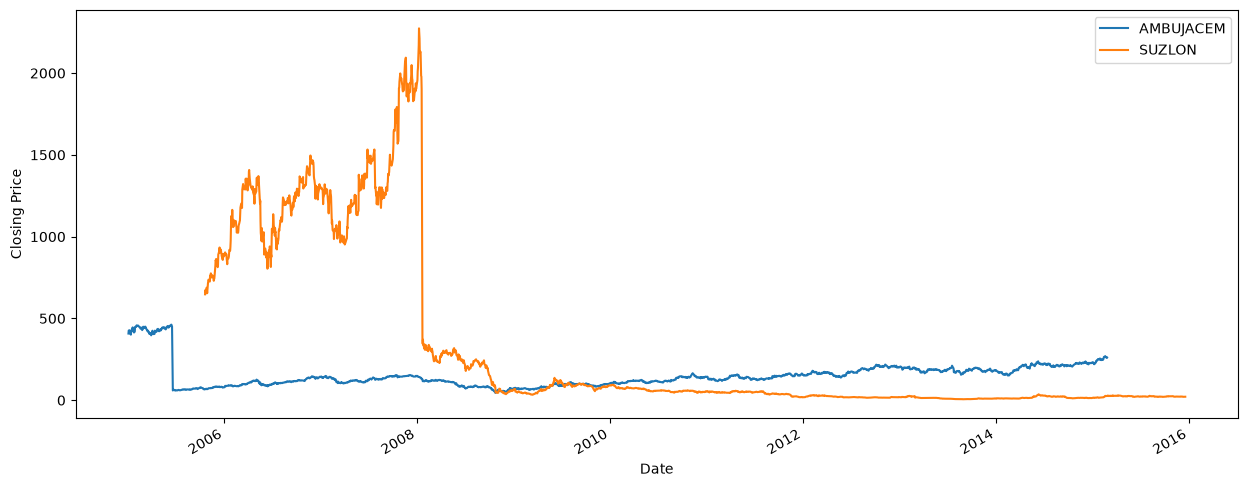

In [38]:
# Sort ascending by date
df_ambuja.sort_index(inplace=True)
df_suzlon.sort_index(inplace=True)

fig, ax = plt.subplots(figsize=(15, 6))
df_ambuja["close"].plot(ax=ax, label="AMBUJACEM")
df_suzlon["close"].plot(ax=ax, label="SUZLON")
ax.set_xlabel("Date")
ax.set_ylabel("Closing Price")
ax.legend()
plt.show()

23. Hitung return harian

Menambah kolom return = close.pct_change() * 100 ke kedua DataFrame. Baris pertama NaN karena tidak ada harga sebelumnya.

In [39]:
# Compute daily returns
df_ambuja["return"] = df_ambuja["close"].pct_change() * 100
df_suzlon["return"] = df_suzlon["close"].pct_change() * 100

print("Ambuja returns (head):")
print(df_ambuja[["close", "return"]].head())
print()
print("Suzlon returns (head):")
print(df_suzlon[["close", "return"]].head())

Ambuja returns (head):
               close    return
date                          
2005-01-03  407.6001       NaN
2005-01-04  425.8501  4.477428
2005-01-05  425.9501  0.023482
2005-01-06  416.0501 -2.324216
2005-01-07  426.3001  2.463646

Suzlon returns (head):
               close    return
date                          
2005-10-20  647.4003       NaN
2005-10-21  673.1503  3.977446
2005-10-24  653.3503 -2.941394
2005-10-25  659.0003  0.864773
2005-10-26  687.9003  4.385430


24. Plot return harian

Membandingkan return harian (%) kedua saham dalam satu grafik.

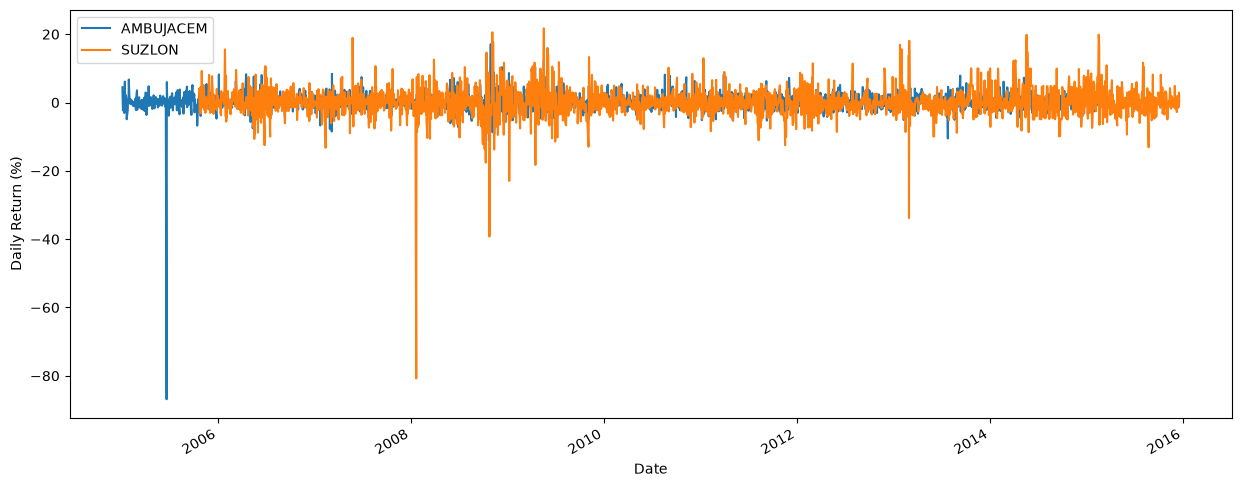

In [40]:
fig, ax = plt.subplots(figsize=(15, 6))
df_ambuja["return"].plot(ax=ax, label="AMBUJACEM")
df_suzlon["return"].plot(ax=ax, label="SUZLON")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (%)")
ax.legend()
plt.show()

25. Checkpoint return

Memastikan kolom return ada, jumlah kolom menjadi 6, dan nilai pertama NaN.

In [41]:
# --- Returns checkpoint ---
assert "return" in df_ambuja.columns, (
    "df_ambuja is missing the 'return' column"
)
assert "return" in df_suzlon.columns, (
    "df_suzlon is missing the 'return' column"
)
assert df_ambuja.shape[1] == 6, (
    f"df_ambuja should have 6 columns (5 + return), "
    f"got {df_ambuja.shape[1]}"
)
assert df_suzlon.shape[1] == 6, (
    f"df_suzlon should have 6 columns (5 + return), "
    f"got {df_suzlon.shape[1]}"
)
# First return should be NaN (no previous price)
assert pd.isna(df_ambuja["return"].iloc[0]), (
    "First return value should be NaN"
)
print(
    "Checkpoint passed: return columns computed correctly."
)

Checkpoint passed: return columns computed correctly.


Kesimpulan Singkat
- Alur kerja sudah modular dan tervalidasi. 
- Notebook membangun pipeline API → DataFrame → SQLite → analisis, dengan dua kelas buatan sendiri: 
    - AlphaVantageAPI (ambil data) 
    - SQLRepository (simpan dan baca data). 
- Setiap tahap dijaga assertion/checkpoint sehingga kesalahan tipe data atau struktur cepat terdeteksi.
- Data tersimpan di database, bukan CSV. 
- Dua saham India (Ambuja Cement dan Suzlon) disimpan ke stocks.sqlite dan dapat dibaca ulang dengan indeks tanggal yang benar.
- Perbedaan karakter kedua saham. 
    - Dari plot, Suzlon cenderung menunjukkan pergerakan harga dan return yang lebih fluktuatif dibanding Ambuja Cement.
- Catatan perhatian: 
    - read_table(limit=2500) hanya mengambil 2.500 baris terakhir, padahal Ambuja punya 5.225 dan Suzlon 5.031 baris. 
    - Karena itu analisis lanjutan hanya mencakup sebagian data 
    - Jika ingin analisis penuh, naikkan atau hapus limit. 
    - Return juga dihitung dengan pct_change, sehingga data yang belum disesuaikan (misalnya stock split) bisa menghasilkan lonjakan semu.
- Langkah lanjut yang disarankan: 
    - hitung statistik risiko (volatilitas, korelasi antar saham, drawdown) dan bandingkan hasilnya.
